## 0. Instalasi & import library

In [ ]:
# !pip install Sastrawi

In [2]:
import re
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
set_seed()
pd.set_option("display.max_colwidth", 100)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


# 1. Eksplorasi Data

### 1.1 Load data

In [3]:
KOLOM = ["Konteks", "Pertanyaan", "Jawaban"]
train_df = pd.read_csv("C:/OneDrive/Documents/KULIAH/Deep Learning/Chatbot Usada/Dataset/train.csv", encoding="utf-8-sig")[KOLOM]
val_df   = pd.read_csv("C:/OneDrive/Documents/KULIAH/Deep Learning/Chatbot Usada/Dataset/valid.csv", encoding="utf-8-sig")[KOLOM]
test_df  = pd.read_csv("C:/OneDrive/Documents/KULIAH/Deep Learning/Chatbot Usada/Dataset/test.csv",  encoding="utf-8-sig")[KOLOM]

# buang baris kosong (file CSV berisi baris tanpa isi di bagian bawah)
print("Sebelum buang baris kosong:", len(train_df), len(val_df), len(test_df))
train_df = train_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)
val_df   = val_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)
test_df  = test_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)
print("Sesudah buang baris kosong :", len(train_df), len(val_df), len(test_df))

for df in (train_df, val_df, test_df):
    for k in KOLOM:
        df[k] = df[k].fillna("").astype(str).str.strip()

train_df.head()

Sebelum buang baris kosong: 1698 1098 1198
Sesudah buang baris kosong : 1050 150 300


,Konteks,Pertanyaan,Jawaban
0,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,Kayu santen berkhasiat untuk meredakan sakit maag.
1,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Penyakit apa yang bisa diredakan dengan kayu santen?,Kayu santen berkhasiat untuk meredakan sakit maag.
2,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,Kayu santen berkhasiat untuk meredakan sakit maag.
3,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Apa fungsi kayu santen sebagai tanaman obat Bali?,Kayu santen berkhasiat untuk meredakan sakit maag.
4,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Manfaat kayu santen sebagai obat tradisional apa?,Kayu santen berkhasiat untuk meredakan sakit maag.


### 1.2 Jumlah data train, validation, dan test

,Split,Jumlah baris,Persentase,Jawaban unik
0,Train,1050,70%,150
1,Validation,150,10%,150
2,Test,300,20%,150
3,Total,1500,100%,150


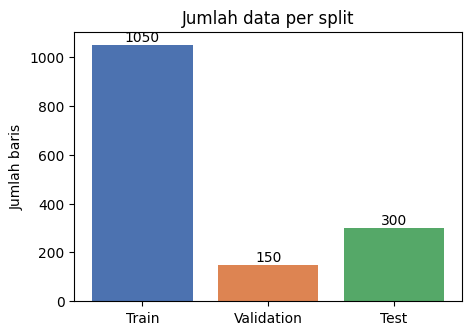

In [4]:
total = len(train_df) + len(val_df) + len(test_df)
ringkasan = pd.DataFrame({
    "Split": ["Train", "Validation", "Test", "Total"],
    "Jumlah baris": [len(train_df), len(val_df), len(test_df), total],
    "Persentase": [f"{len(d)/total:.0%}" for d in (train_df, val_df, test_df)] + ["100%"],
    "Jawaban unik": [d["Jawaban"].nunique() for d in (train_df, val_df, test_df)]
                    + [pd.concat([train_df, val_df, test_df])["Jawaban"].nunique()],
})
display(ringkasan)

plt.figure(figsize=(5, 3.5))
bar = plt.bar(ringkasan["Split"][:3], ringkasan["Jumlah baris"][:3], color=["#4C72B0", "#DD8452", "#55A868"])
plt.bar_label(bar)
plt.title("Jumlah data per split"); plt.ylabel("Jumlah baris"); plt.show()

### 1.3 Cek missing value, duplikat, dan kebocoran data

In [6]:
semua = pd.concat([train_df, val_df, test_df])
print("Missing value:\n", semua.replace("", np.nan).isna().sum(), "\n")

norm = lambda s: s.str.lower().str.strip()
print("Pertanyaan duplikat (seluruh split):", norm(semua["Pertanyaan"]).duplicated().sum())

# setiap jawaban di val/test harus ada di train, karena model hanya bisa memilih kelas yang pernah dipelajari
print("Semua jawaban val ada di train :", set(val_df.Jawaban) <= set(train_df.Jawaban))
print("Semua jawaban test ada di train:", set(test_df.Jawaban) <= set(train_df.Jawaban))

# kalimat pertanyaan val/test tidak boleh sama persis dengan train
q_train = set(norm(train_df["Pertanyaan"]))
print("Pertanyaan val yang sama dengan train :", norm(val_df["Pertanyaan"]).isin(q_train).sum())
print("Pertanyaan test yang sama dengan train:", norm(test_df["Pertanyaan"]).isin(q_train).sum())

Missing value:
 Konteks       0
Pertanyaan    0
Jawaban       0
dtype: int64 

Pertanyaan duplikat (seluruh split): 0
Semua jawaban val ada di train : True
Semua jawaban test ada di train: True
Pertanyaan val yang sama dengan train : 0
Pertanyaan test yang sama dengan train: 0


### 1.4 Kata yang paling sering muncul pada pertanyaan

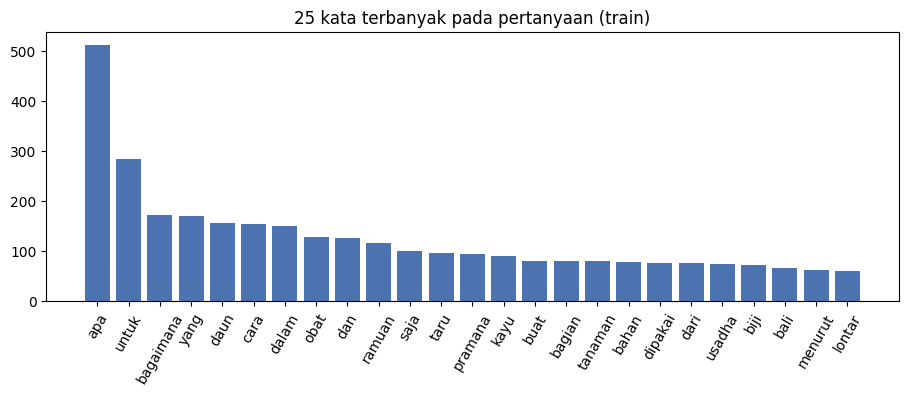

Jumlah kata unik pertanyaan train: 882


In [8]:
kata = Counter(w for q in train_df["Pertanyaan"].str.lower() for w in re.findall(r"[a-z]+", q))
top = pd.DataFrame(kata.most_common(25), columns=["kata", "frekuensi"])

plt.figure(figsize=(11, 3.5))
plt.bar(top["kata"], top["frekuensi"], color="#4C72B0")
plt.xticks(rotation=60); plt.title("25 kata terbanyak pada pertanyaan (train)"); plt.show()
print("Jumlah kata unik pertanyaan train:", len(kata))

# 2. Preprocessing

### Preprocessing 1: Case folding

In [9]:
def case_folding(text):
    return text.lower()

for df in (train_df, val_df, test_df):
    df["q"] = df["Pertanyaan"].apply(case_folding)

train_df[["Pertanyaan", "q"]].head(3)

,Pertanyaan,q
0,Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,apa khasiat kayu santen menurut lontar usadha taru pramana?
1,Penyakit apa yang bisa diredakan dengan kayu santen?,penyakit apa yang bisa diredakan dengan kayu santen?
2,Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,kayu santen berkhasiat untuk apa dalam lontar taru pramana?


### Preprocessing 2: Cleaning

In [10]:
def cleaning(text):
    text = re.sub(r"[-–—/]", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for df in (train_df, val_df, test_df):
    df["q"] = df["q"].apply(cleaning)

train_df[["Pertanyaan", "q"]].head(3)

,Pertanyaan,q
0,Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,apa khasiat kayu santen menurut lontar usadha taru pramana
1,Penyakit apa yang bisa diredakan dengan kayu santen?,penyakit apa yang bisa diredakan dengan kayu santen
2,Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,kayu santen berkhasiat untuk apa dalam lontar taru pramana


### Preprocessing 3: Normalisasi kata tidak baku

In [11]:
kamus_normalisasi = {
    "gmn": "bagaimana", "gimana": "bagaimana", "gmana": "bagaimana",
    "bikin": "membuat", "dibikin": "dibuat", "bikinnya": "membuatnya",
    "gak": "tidak", "ga": "tidak", "gk": "tidak", "nggak": "tidak", "tdk": "tidak",
    "aja": "saja", "yg": "yang", "dgn": "dengan", "utk": "untuk", "sama": "dan",
    "dipake": "dipakai", "pake": "pakai", "ngobatin": "mengobati", "ngambil": "mengambil",
    "ngejelasin": "menjelaskan", "disimpen": "disimpan", "dapet": "dapat",
    "kulkas": "lemari es", "mencret": "diare", "serai": "sereh",
}

def normalisasi(text):
    return " ".join(kamus_normalisasi.get(w, w) for w in text.split())

for df in (train_df, val_df, test_df):
    df["q"] = df["q"].apply(normalisasi)

contoh = train_df[train_df["Pertanyaan"].str.lower().str.contains(r"\b(?:gimana|bikin|aja|gak)\b")]
contoh[["Pertanyaan", "q"]].head()

,Pertanyaan,q
13,isi ajaran taru pramana soal tumbuhan obat apa aja,isi ajaran taru pramana soal tumbuhan obat apa saja
20,kayu santen bisa buat radang lambung gak,kayu santen bisa buat radang lambung tidak
32,cara bikin usadha kayu santen di rumah,cara membuat usadha kayu santen di rumah
75,cara pakai boreh kencur gimana,cara pakai boreh kencur bagaimana
101,minyak cem-ceman dipakai gimana buat rambut dan aromaterapi,minyak cem ceman dipakai bagaimana buat rambut dan aromaterapi


### Preprocessing 4: Stopword removal

In [12]:
stopword_sastrawi = set(StopWordRemoverFactory().get_stop_words())

kata_dipertahankan = {
    "apa", "apakah", "bagaimana", "mengapa", "kenapa", "kapan", "berapa", "siapa", "mana",
    "tidak", "boleh", "harus", "sebelum", "setelah",
}
stopwords = (stopword_sastrawi - kata_dipertahankan) | {"sih", "ya", "dong", "nih", "deh", "tuh", "kok"}

print("Jumlah stopword Sastrawi                 :", len(stopword_sastrawi))
print("Kata penting di Sastrawi (dipertahankan) :", sorted(stopword_sastrawi & kata_dipertahankan))
print("Jumlah stopword yang dipakai             :", len(stopwords))

def hapus_stopword(text):
    return " ".join(w for w in text.split() if w not in stopwords)

q_contoh = "mengapa biji saga harus dihindari saat mengolah daun saga"
print("\nContoh             :", q_contoh)
print("Stopword Sastrawi  :", " ".join(w for w in q_contoh.split() if w not in stopword_sastrawi))
print("Stopword disesuaikan:", hapus_stopword(q_contoh))

for df in (train_df, val_df, test_df):
    df["q"] = df["q"].apply(hapus_stopword)

train_df[["Pertanyaan", "q"]].sample(5, random_state=SEED)

Jumlah stopword Sastrawi                 : 123
Kata penting di Sastrawi (dipertahankan) : ['apakah', 'boleh', 'harus', 'kenapa', 'mengapa', 'sebelum', 'setelah', 'tidak']
Jumlah stopword yang dipakai             : 121

Contoh             : mengapa biji saga harus dihindari saat mengolah daun saga
Stopword Sastrawi  : biji saga dihindari mengolah daun saga
Stopword disesuaikan: mengapa biji saga harus dihindari mengolah daun saga


,Pertanyaan,q
352,Bisa tolong jelaskan apa definisi Usadha Taru Pramana menurut tradisi Bali?,jelaskan apa definisi usadha taru pramana tradisi bali
689,Tabia Dadap bisa dipakai buat obat apa saja dalam pengobatan Bali?,tabia dadap dipakai buat obat apa pengobatan bali
485,Bagaimana peranan cuka atau arak dalam proses penyerapan zat herbal lewat kulit?,bagaimana peranan cuka arak proses penyerapan zat herbal lewat kulit
388,Pohon beringin hadir pertama kali menghadap siapa dalam ajaran Taru Pramana?,pohon beringin hadir pertama kali menghadap siapa ajaran taru pramana
31,Langkah meracik ramuan kayu santen bagaimana?,langkah meracik ramuan kayu santen bagaimana


### Preprocessing 5: Stemming

In [13]:
stemmer = StemmerFactory().create_stemmer()
_cache = {}
def stem_kata(w):
    if w not in _cache:
        _cache[w] = stemmer.stem(w)
    return _cache[w]

def stemming(text):
    return " ".join(stem_kata(w) for w in text.split())

for df in (train_df, val_df, test_df):
    df["sebelum_stemming"] = df["q"]
    df["q"] = df["q"].apply(stemming)

train_df[["sebelum_stemming", "q"]].rename(columns={"q": "sesudah_stemming"}).head(10)

,sebelum_stemming,sesudah_stemming
0,apa khasiat kayu santen lontar usadha taru pramana,apa khasiat kayu santen lontar usadha taru pramana
1,penyakit apa diredakan kayu santen,sakit apa reda kayu santen
2,kayu santen berkhasiat apa lontar taru pramana,kayu santen khasiat apa lontar taru pramana
3,apa fungsi kayu santen tanaman obat bali,apa fungsi kayu santen tanam obat bal
4,manfaat kayu santen obat tradisional apa,manfaat kayu santen obat tradisional apa
5,kegunaan kayu santen usadha taru pramana,guna kayu santen usadha taru pramana
6,tanaman kayu santen dipakai mengobati keluhan apa,tanam kayu santen pakai obat keluh apa
7,informasi apa dijelaskan ajaran taru pramana mengenai tumbuhan obat,informasi apa jelas ajar taru pramana kena tumbuh obat
8,informasi tumbuhan obat apa termuat taru pramana,informasi tumbuh obat apa muat taru pramana
9,apa cakupan pengetahuan tanaman obat ajaran taru pramana,apa cakup tahu tanam obat ajar taru pramana


### Preprocessing 6: Tokenisasi

In [14]:
for df in (train_df, val_df, test_df):
    df["tokens"] = df["q"].str.split()

train_df[["q", "tokens"]].head(3)

,q,tokens
0,apa khasiat kayu santen lontar usadha taru pramana,"[apa, khasiat, kayu, santen, lontar, usadha, taru, pramana]"
1,sakit apa reda kayu santen,"[sakit, apa, reda, kayu, santen]"
2,kayu santen khasiat apa lontar taru pramana,"[kayu, santen, khasiat, apa, lontar, taru, pramana]"


### Preprocessing 7: Membangun vocabulary (hanya dari train)

In [15]:
PAD, OOV = "<PAD>", "<OOV>"

def build_vocab(token_lists):
    w2i = {PAD: 0, OOV: 1}
    for w, _ in Counter(t for toks in token_lists for t in toks).most_common():
        w2i[w] = len(w2i)
    return w2i

word2idx = build_vocab(train_df["tokens"])
VOCAB_SIZE = len(word2idx)
print("Ukuran vocabulary:", VOCAB_SIZE)

Ukuran vocabulary: 662


### Preprocessing 8: Konversi token ke angka (sequence)

In [16]:
def to_seq(tokens, w2i):
    return [w2i.get(t, w2i[OOV]) for t in tokens]

for df in (train_df, val_df, test_df):
    df["seq"] = df["tokens"].apply(lambda t: to_seq(t, word2idx))

train_df[["tokens", "seq"]].head(3)

,tokens,seq
0,"[apa, khasiat, kayu, santen, lontar, usadha, taru, pramana]","[2, 22, 13, 52, 23, 18, 11, 12]"
1,"[sakit, apa, reda, kayu, santen]","[14, 2, 261, 13, 52]"
2,"[kayu, santen, khasiat, apa, lontar, taru, pramana]","[13, 52, 22, 2, 23, 11, 12]"


### Preprocessing 9: Padding

In [17]:
MAX_LEN = int(train_df["seq"].str.len().max()) + 2

def pad(seqs, maxlen=MAX_LEN):
    return keras.utils.pad_sequences(seqs, maxlen=maxlen, padding="post", truncating="post")

X_train = pad(train_df["seq"].tolist())
X_val   = pad(val_df["seq"].tolist())
X_test  = pad(test_df["seq"].tolist())
print("MAX_LEN:", MAX_LEN)
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

MAX_LEN: 16
X_train: (1050, 16) | X_val: (150, 16) | X_test: (300, 16)


### Preprocessing 10: Label encoding

In [18]:
daftar_jawaban = list(dict.fromkeys(train_df["Jawaban"]))   # urutan kemunculan di train
jawaban2id = {j: i for i, j in enumerate(daftar_jawaban)}
id2jawaban = {i: j for j, i in jawaban2id.items()}
NUM_CLASSES = len(jawaban2id)

y_train = train_df["Jawaban"].map(jawaban2id).values
y_val   = val_df["Jawaban"].map(jawaban2id).values
y_test  = test_df["Jawaban"].map(jawaban2id).values
assert not (pd.isna(y_val).any() or pd.isna(y_test).any()), "Ada jawaban val/test yang tidak ada di train"

print("Jumlah kelas:", NUM_CLASSES)
print("Contoh: kelas 0 →", id2jawaban[0][:80], "...")

Jumlah kelas: 150
Contoh: kelas 0 → Kayu santen berkhasiat untuk meredakan sakit maag. ...


# 3. Model LSTM

### Arsitektur

| Teknik | Nilai | Letak | Fungsi |
|---|---|---|---|
| **L2 regularization** | λ = 1e-4 | Embedding, LSTM (kernel & recurrent), Dense | menambahkan penalti `λ·Σw²` ke loss sehingga bobot tidak tumbuh terlalu besar |
| **SpatialDropout1D** | 0,3 | setelah Embedding | mematikan seluruh dimensi embedding tertentu secara acak untuk satu kalimat |
| **Dropout input LSTM** | 0,3 | di dalam LSTM | mematikan sebagian input yang masuk ke LSTM pada setiap langkah |
| **Dropout** | 0,5 | setelah LSTM & setelah Dense | mematikan 50% neuron secara acak agar model tidak bergantung pada neuron tertentu |
| **EarlyStopping** (callback) | patience 20 | proses training | menghentikan training saat `val_loss` tidak membaik, lalu mengembalikan bobot ke epoch terbaik |

In [27]:
CONFIG = dict(
    embed_dim=128,
    lstm_units=128,
    dense_units=128,
    l2=1e-4,              # kekuatan L2 regularization (λ)
    emb_dropout=0.3,      # SpatialDropout1D setelah embedding
    lstm_dropout=0.3,     # dropout input di dalam LSTM
    dropout=0.5,          # dropout setelah LSTM & Dense
    learning_rate=1e-3,
)

def build_model(vocab_size, max_len, num_classes, cfg=CONFIG):
    reg = regularizers.l2(cfg["l2"])
    model = keras.Sequential([
        layers.Input(shape=(max_len,)),
        layers.Embedding(vocab_size, cfg["embed_dim"], mask_zero=True, embeddings_regularizer=reg),
        layers.SpatialDropout1D(cfg["emb_dropout"]),
        layers.LSTM(cfg["lstm_units"], dropout=cfg["lstm_dropout"],
                    kernel_regularizer=reg, recurrent_regularizer=reg),
        layers.Dropout(cfg["dropout"]),
        layers.Dense(cfg["dense_units"], activation="relu", kernel_regularizer=reg),
        layers.Dropout(cfg["dropout"]),
        layers.Dense(num_classes, activation="softmax", kernel_regularizer=reg),
    ], name="lstm_chatbot")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=cfg["learning_rate"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_model(VOCAB_SIZE, MAX_LEN, NUM_CLASSES)

# 4. Training

In [20]:
EPOCHS = 300
BATCH_SIZE = 16

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # pantau loss pada data validasi
    patience=20,                 # toleransi 20 epoch tanpa perbaikan
    restore_best_weights=True,   # kembalikan bobot dari epoch terbaik
    verbose=1,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=[early_stop],
    verbose=2,
)

Epoch 1/300
66/66 - 5s - 81ms/step - accuracy: 0.0057 - loss: 5.0588 - val_accuracy: 0.0200 - val_loss: 5.0402
Epoch 2/300
66/66 - 1s - 17ms/step - accuracy: 0.0248 - loss: 5.0329 - val_accuracy: 0.1533 - val_loss: 5.0136
Epoch 3/300
66/66 - 1s - 20ms/step - accuracy: 0.0314 - loss: 4.9625 - val_accuracy: 0.0867 - val_loss: 4.7246
Epoch 4/300
66/66 - 1s - 20ms/step - accuracy: 0.0543 - loss: 4.4755 - val_accuracy: 0.1400 - val_loss: 3.8518
Epoch 5/300
66/66 - 1s - 19ms/step - accuracy: 0.1162 - loss: 3.7627 - val_accuracy: 0.2933 - val_loss: 2.9918
Epoch 6/300
66/66 - 1s - 18ms/step - accuracy: 0.1676 - loss: 3.2935 - val_accuracy: 0.4133 - val_loss: 2.5932
Epoch 7/300
66/66 - 1s - 18ms/step - accuracy: 0.2133 - loss: 2.9504 - val_accuracy: 0.4667 - val_loss: 2.2935
Epoch 8/300
66/66 - 1s - 22ms/step - accuracy: 0.2648 - loss: 2.7310 - val_accuracy: 0.5933 - val_loss: 2.0438
Epoch 9/300
66/66 - 1s - 19ms/step - accuracy: 0.3114 - loss: 2.4510 - val_accuracy: 0.5800 - val_loss: 1.8406
E

### Grafik loss & akurasi

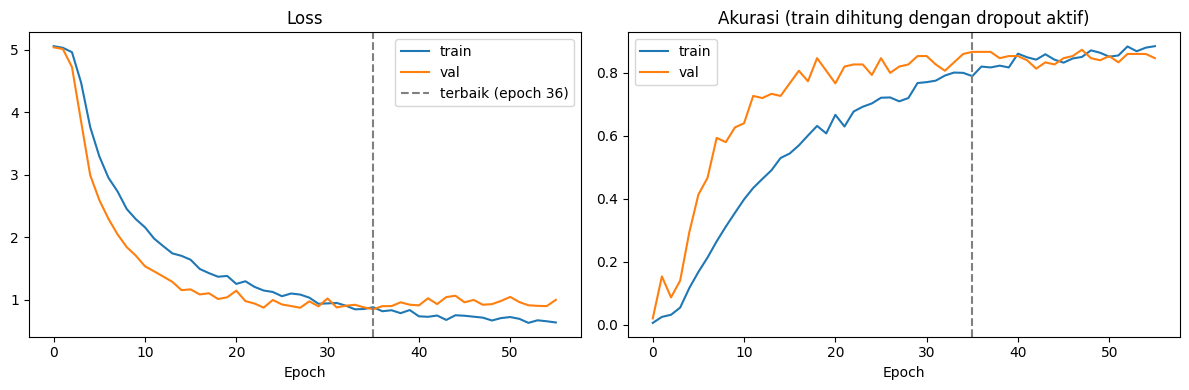

Epoch terbaik: 36 | val_loss: 0.8470
Akurasi train: 0.9829 | val: 0.8667 | selisih (indikasi overfitting): 0.1162
Total epoch dijalankan: 56


In [21]:
h = history.history
terbaik = int(np.argmin(h["val_loss"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
ax[0].axvline(terbaik, ls="--", c="gray", label=f"terbaik (epoch {terbaik+1})")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val")
ax[1].axvline(terbaik, ls="--", c="gray")
ax[1].set_title("Akurasi (train dihitung dengan dropout aktif)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Epoch terbaik: {terbaik+1} | val_loss: {h['val_loss'][terbaik]:.4f}")

# akurasi dihitung ulang tanpa dropout (dropout hanya aktif saat training,
# sehingga akurasi train di grafik terlihat lebih rendah dari sebenarnya)
acc_train = model.evaluate(X_train, y_train, verbose=0)[1]
acc_val   = model.evaluate(X_val, y_val, verbose=0)[1]
print(f"Akurasi train: {acc_train:.4f} | val: {acc_val:.4f} | selisih (indikasi overfitting): {acc_train - acc_val:.4f}")
print(f"Total epoch dijalankan: {len(h['loss'])}")

# 5. Evaluasi

### Metrik pada data test

In [22]:
def evaluasi(model, X, y):
    prob = model.predict(X, verbose=0)
    pred = prob.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f1,
    }, prob, pred

skor_test, prob_test, pred_test = evaluasi(model, X_test, y_test)
display(pd.DataFrame([skor_test], index=["Test"]).round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Test,0.8233,0.8398,0.8233,0.8054


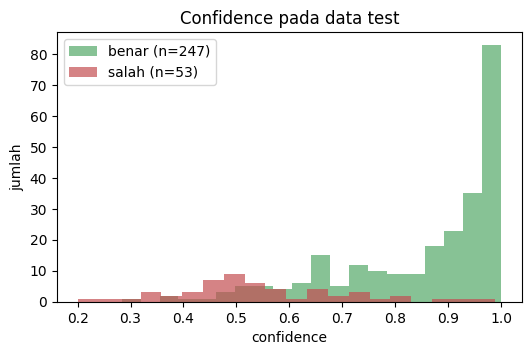

Rata-rata confidence benar: 0.854 | salah: 0.549


In [26]:
conf = prob_test.max(axis=1)
benar = pred_test == y_test
plt.figure(figsize=(6, 3.5))
plt.hist(conf[benar], bins=20, alpha=0.7, label=f"benar (n={benar.sum()})", color="#55A868")
plt.hist(conf[~benar], bins=20, alpha=0.7, label=f"salah (n={(~benar).sum()})", color="#C44E52")
plt.xlabel("confidence"); plt.ylabel("jumlah"); plt.legend(); plt.title("Confidence pada data test")
plt.show()
print(f"Rata-rata confidence benar: {conf[benar].mean():.3f} | salah: {conf[~benar].mean() if (~benar).any() else float('nan'):.3f}")